# YOLO World Fine-Tuning for Fish Detection

This notebook fine-tunes `yolov8x-worldv2` on a labeled fish dataset so it performs better on underwater footage.

**Designed for Google Colab with GPU runtime (T4 or better).**

### Steps
1. Check GPU & install dependencies
2. Mount Google Drive
3. Load local training dataset from `Batch01_Training_Data` on Drive
4. Fine-tune YOLO World
5. Evaluate results
6. Save fine-tuned weights & use in `model_runner.py`

In [2]:
# @title 1. Check GPU
!nvidia-smi

Thu Apr 16 22:52:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   30C    P0             43W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [8]:
# @title 2. Install dependencies
!pip install -q ultralytics supervision opencv-python-headless

In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os
from pathlib import Path
import sys

# ── Paths (edit these) ────────────────────────────────────────────────────
DRIVE_ROOT          = '/content/drive/MyDrive'
VIDEO_INPUT_FOLDER  = os.path.join(DRIVE_ROOT, 'demo_vids')
VIDEO_OUTPUT_FOLDER = os.path.join(DRIVE_ROOT, 'demo_vids', 'output')
Training_DATASET_PATH = os.path.join(DRIVE_ROOT, 'Batch01_Training_Data', 'Photos')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# @title 4. Imports
import os
from pathlib import Path
from ultralytics import YOLOWorld
import yaml

## Dataset

Training data is loaded directly from **`Batch01_Training_Data`** in your Google Drive. The dataset must be in YOLO format with the following structure:

```
Batch01_Training_Data/
├── data.yaml
├── train/
│   ├── images/
│   └── labels/
├── valid/
│   ├── images/
│   └── labels/
└── test/          # optional
    ├── images/
    └── labels/
```

In [13]:
# @title 5. Build YOLO dataset from real annotations
import glob, shutil, random, os
import pandas as pd
from pathlib import Path

# ── Load annotations ──────────────────────────────────────────────────────
ANNO_CSV      = os.path.join(DRIVE_ROOT, 'Batch01_Training_Data', 'batch01_species_annotations.csv')
LABEL_MAP_CSV = os.path.join(DRIVE_ROOT, 'Batch01_Training_Data', 'batch01_label_map.csv')

df        = pd.read_csv(ANNO_CSV)
label_map = pd.read_csv(LABEL_MAP_CSV).set_index('label')['label_id'].to_dict()

# Drop degenerate boxes (zero width or height)
df = df[(df['x2'] - df['x1'] > 0) & (df['y2'] - df['y1'] > 0)].copy()
print(f"Loaded {len(df)} annotations across {df['filename'].nunique()} images")

# Drop annotations whose label isn't in the label map
unknown = df[~df['label'].isin(label_map)]
if len(unknown):
    print(f"WARNING: {len(unknown)} annotations with unknown labels dropped: {unknown['label'].unique()}")
df = df[df['label'].isin(label_map)]

# ── Find images on Drive ───────────────────────────────────────────────────
matches = glob.glob(os.path.join(DRIVE_ROOT, '**/Batch01_Training_Data'), recursive=True)
if not matches:
    raise FileNotFoundError("'Batch01_Training_Data' not found under MyDrive")
BATCH_DIR  = matches[0]
PHOTOS_DIR = os.path.join(BATCH_DIR, 'Photos') if os.path.isdir(os.path.join(BATCH_DIR, 'Photos')) else BATCH_DIR

# Build filename → full path lookup
img_paths = (
    glob.glob(os.path.join(PHOTOS_DIR, '*.jpg')) +
    glob.glob(os.path.join(PHOTOS_DIR, '*.jpeg')) +
    glob.glob(os.path.join(PHOTOS_DIR, '*.png'))
)
img_lookup = {os.path.basename(p): p for p in img_paths}

# Keep only images that exist on disk
annotated_files = df['filename'].unique()
found     = [f for f in annotated_files if f in img_lookup]
not_found = [f for f in annotated_files if f not in img_lookup]
if not_found:
    print(f"WARNING: {len(not_found)} annotated images not found on disk — skipping")
df = df[df['filename'].isin(found)]
print(f"Matched {len(found)} images on disk")

# ── 80/20 train/val split ─────────────────────────────────────────────────
IMAGE_DIM = (1920, 1080)  # width, height — all images are 1920×1080

DATASET_DIR = '/content/dataset'
for split in ('train/images', 'train/labels', 'valid/images', 'valid/labels'):
    os.makedirs(os.path.join(DATASET_DIR, split), exist_ok=True)

random.shuffle(found)
split_idx   = int(len(found) * 0.8)
train_imgs  = found[:split_idx]
val_imgs    = found[split_idx:]
split_map   = {f: 'train' for f in train_imgs}
split_map.update({f: 'valid' for f in val_imgs})

# ── Copy images & write YOLO .txt labels ──────────────────────────────────
IMG_W, IMG_H = IMAGE_DIM

for filename, group in df.groupby('filename'):
    split = split_map[filename]

    # Copy image
    shutil.copy2(img_lookup[filename], os.path.join(DATASET_DIR, split, 'images', filename))

    # Write YOLO label file  (cx cy w h  — all normalized 0-1)
    label_path = os.path.join(DATASET_DIR, split, 'labels', Path(filename).stem + '.txt')
    with open(label_path, 'w') as f:
        for _, row in group.iterrows():
            cls_id = label_map[row['label']]
            bw = (row['x2'] - row['x1']) / IMG_W
            bh = (row['y2'] - row['y1']) / IMG_H
            cx = (row['x1'] + row['x2']) / 2 / IMG_W
            cy = (row['y1'] + row['y2']) / 2 / IMG_H
            f.write(f"{cls_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")

print(f"\nTrain: {len(train_imgs)} images | Val: {len(val_imgs)} images")
print(f"Labels written to {DATASET_DIR}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Batch01_Training_Data/batch01_species_annotations.csv'

In [ ]:
# @title 6. Write data.yaml
import yaml

label_df   = pd.read_csv(LABEL_MAP_CSV).sort_values('label_id')
class_names = label_df['label'].tolist()  # ordered by label_id 0..141

DATA_YAML = os.path.join(DATASET_DIR, 'data.yaml')
data_cfg  = {
    'train': os.path.join(DATASET_DIR, 'train', 'images'),
    'val':   os.path.join(DATASET_DIR, 'valid', 'images'),
    'nc':    len(class_names),
    'names': class_names,
}
with open(DATA_YAML, 'w') as f:
    yaml.dump(data_cfg, f, default_flow_style=False, allow_unicode=True)

print(f"data.yaml written → {DATA_YAML}")
print(f"nc = {len(class_names)} classes")
print("First 5 classes:", class_names[:5])

/usr/local/lib/python3.12/dist-packages/clip/clip.py:64: UserWarning: /root/.cache/clip/ViT-B-32.pt exists, but the SHA256 checksum does not match; re-downloading the file
  warnings.warn(f"{download_target} exists, but the SHA256 checksum does not match; re-downloading the file")
100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 350MiB/s]


Labeled 384 images in /content/dataset/train/images
Labeled 96 images in /content/dataset/valid/images

data.yaml written to: /content/dataset/data.yaml
names:
- fish
- shark
- ray
- eel
- sea turtle
- jellyfish
- octopus
- crab
- shrimp
- lobster
- starfish
nc: 11
train: /content/dataset/train/images
val: /content/dataset/valid/images



In [ ]:
# @title 7. Verify dataset structure
for split in ('train', 'valid'):
    imgs   = glob.glob(os.path.join(DATASET_DIR, split, 'images', '*'))
    labels = glob.glob(os.path.join(DATASET_DIR, split, 'labels', '*.txt'))
    print(f"{split}: {len(imgs)} images, {len(labels)} label files")

train: 384 images, 384 label files
valid: 96 images, 96 label files


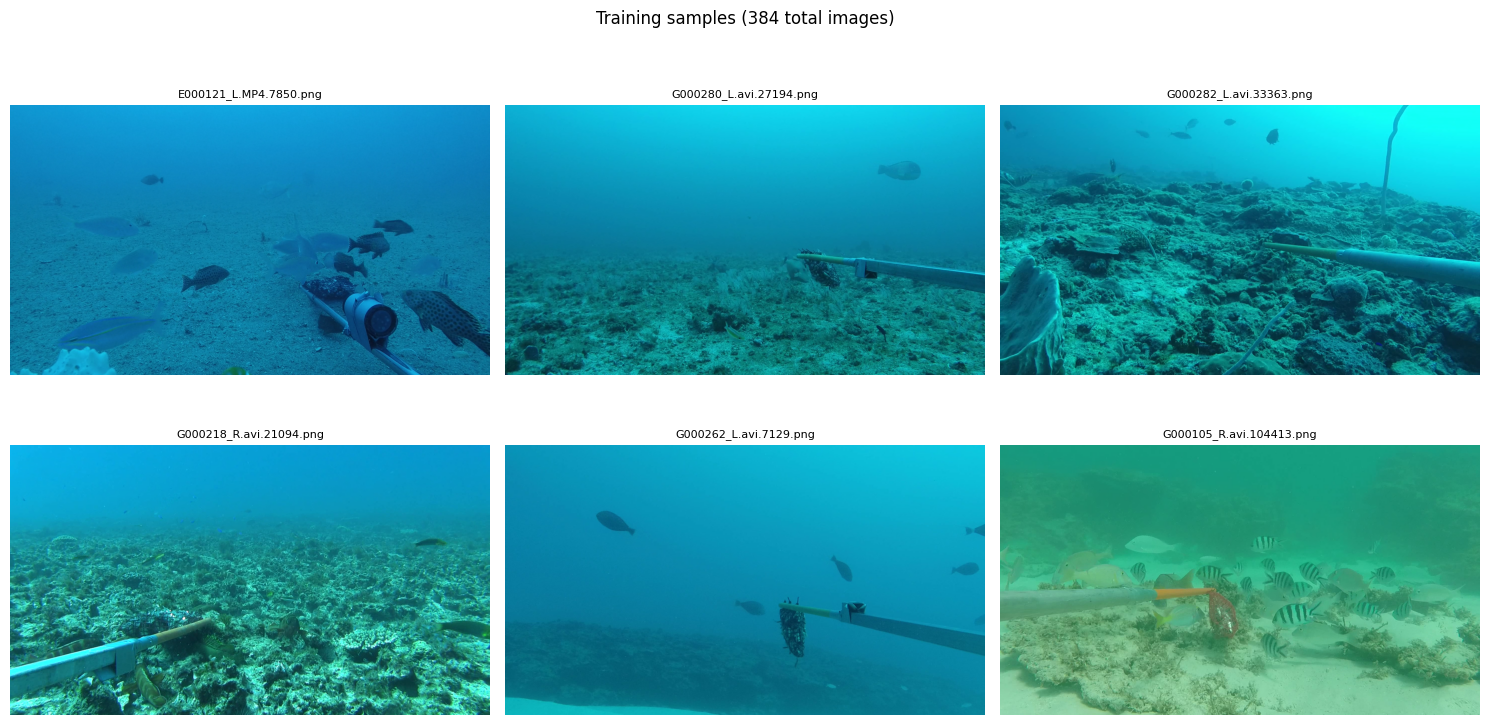

In [ ]:
# @title 8. Visualize sample training images
import cv2
import random
import matplotlib.pyplot as plt

train_img_dir = Path(DATASET_DIR) / 'train' / 'images'
images = list(train_img_dir.glob('*.jpg')) + list(train_img_dir.glob('*.png'))
samples = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, img_path in zip(axes.flat, samples):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=8)
    ax.axis('off')
plt.suptitle(f'Training samples ({len(images)} total images)', fontsize=12)
plt.tight_layout()
plt.show()

## Fine-Tuning

We load `yolov8x-worldv2.pt` and call `.train()`. YOLO World uses a CLIP-style text encoder that links class names to visual features — fine-tuning updates both the vision backbone and the detection head on your labeled data.

| Param | Value | Notes |
|---|---|---|
| `epochs` | 50 | Increase to 100 if time allows |
| `imgsz` | 640 | Match inference resolution |
| `batch` | 16 | Lower to 8 if CUDA OOM |
| `lr0` | 1e-4 | Low LR for fine-tuning |
| `freeze` | 10 | Freeze first 10 backbone layers |
| `close_mosaic` | 10 | Disable mosaic augmentation last 10 epochs |

In [ ]:
# @title 9. Load YOLO World base model
MODEL_PATH = '/content/drive/MyDrive/nat-geo/yolov8x-worldv2.pt'

if not os.path.exists(MODEL_PATH):
    print('Model not found on Drive, downloading from Ultralytics...')
    MODEL_PATH = 'yolov8x-worldv2.pt'

model = YOLOWorld(MODEL_PATH)
print(f'Loaded: {MODEL_PATH}')

Model not found on Drive, downloading from Ultralytics...
Loaded: yolov8x-worldv2.pt


In [ ]:
# @title 10. Fine-tune
RUN_DIR = '/content/drive/MyDrive/nat-geo/runs/yoloworld_fish_ft'

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    lr0=1e-4,
    lrf=0.01,
    warmup_epochs=3,
    close_mosaic=10,
    freeze=0,          # ← changed: unfreeze all layers, real labels warrant it
    optimizer='AdamW',
    weight_decay=0.0005,
    patience=20,
    device=0,
    project='/content/drive/MyDrive/nat-geo/runs',
    name='yoloworld_fish_ft',
    exist_ok=True,
    verbose=True,
)

print('Training complete!')

Ultralytics 8.4.37 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8x-worldv2.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yoloworld_fish_ft, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True,

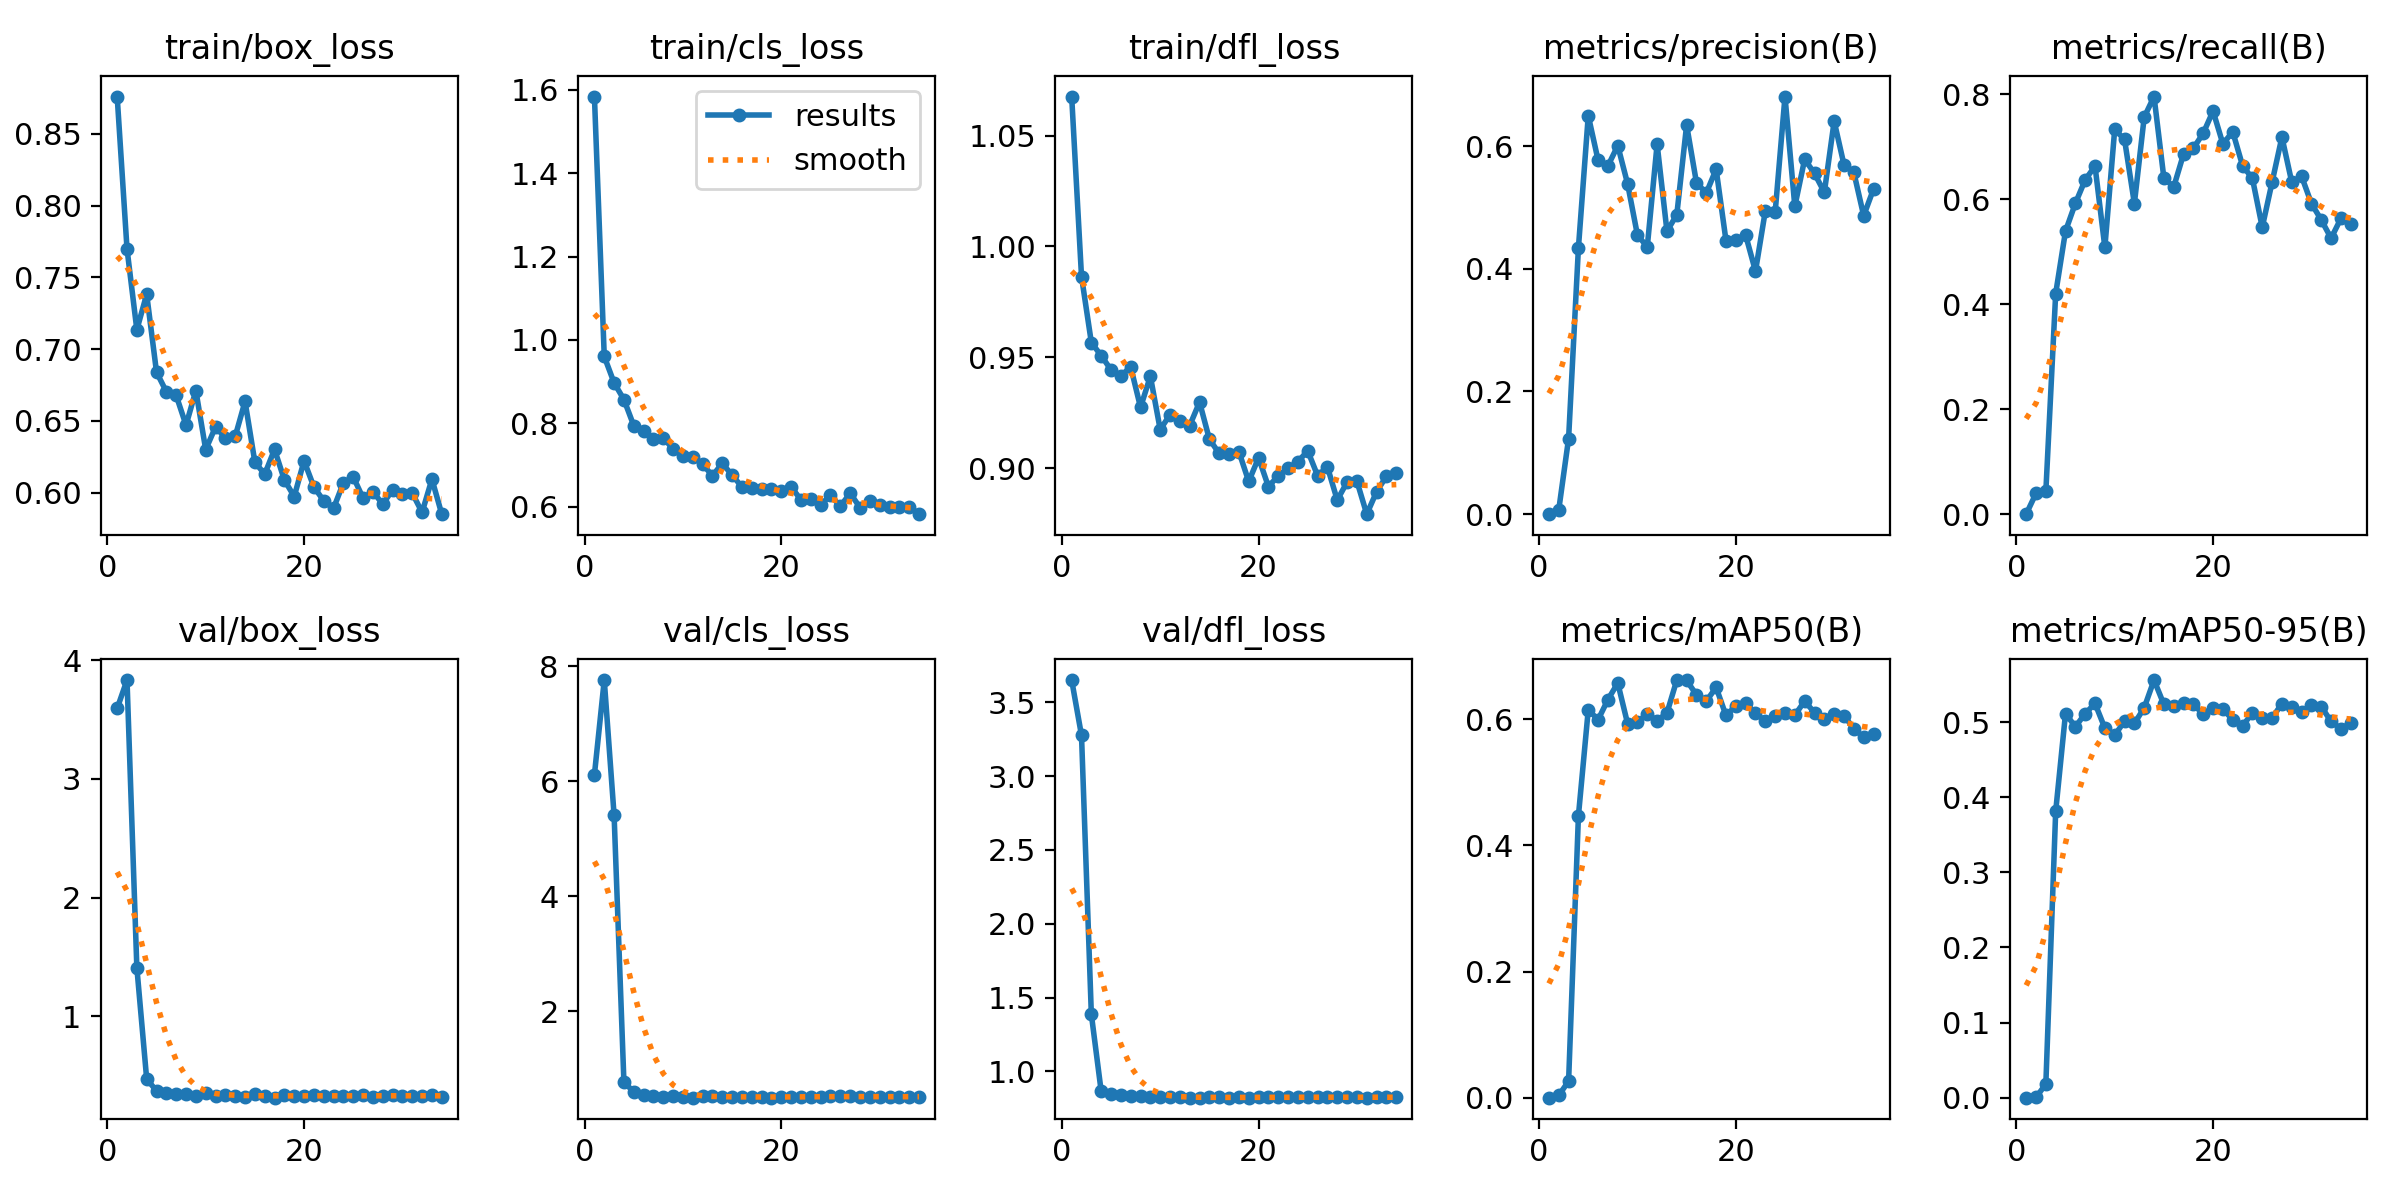

In [ ]:
# @title 11. Plot training curves
from IPython.display import Image, display

result_plot = os.path.join(RUN_DIR, 'results.png')
if os.path.exists(result_plot):
    display(Image(result_plot))
else:
    print(f'results.png not found at {result_plot} — check RUN_DIR')

In [ ]:
# @title 12. Evaluate on validation set
BEST_WEIGHTS = os.path.join(RUN_DIR, 'weights', 'best.pt')

eval_model = YOLOWorld(BEST_WEIGHTS)
metrics = eval_model.val(data=DATA_YAML, imgsz=640, device=0)

print(f"mAP50:     {metrics.box.map50:.4f}")
print(f"mAP50-95:  {metrics.box.map:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall:    {metrics.box.mr:.4f}")

Ultralytics 8.4.37 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8x-worldv2 summary (fused): 128 layers, 72,856,217 parameters, 0 gradients, 276.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3962.7±1955.5 MB/s, size: 1850.2 KB)
val: Scanning /content/dataset/valid/labels.cache... 96 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 96/96 31.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.7s/it 10.2s.7ss
                   all         96        644      0.478      0.781       0.66      0.556
                  fish         93        611      0.691      0.959      0.932      0.883
                 shark         12         13      0.315      0.692      0.602       0.48
                   eel          6          7      0.501      0.857      0.607      0.552
            sea turtle         12         13      0.405      0.615        0.5      0.308
Speed: 4.7ms preprocess, 44.0ms 

In [ ]:
# @title 13. Test inference on a sample video
import os, glob, shutil, subprocess
subprocess.run(['pip', 'install', '-q', 'supervision'], check=True)

import supervision as sv
import cv2
from pathlib import Path
from ultralytics import YOLOWorld

DRIVE_ROOT        = '/content/drive/MyDrive'
VIDEO_INPUT_FOLDER = os.path.join(DRIVE_ROOT, 'demo_vids')
VIDEO_OUTPUT_FOLDER = os.path.join(DRIVE_ROOT, 'demo_vids', 'output')
BEST_WEIGHTS      = '/content/drive/MyDrive/nat-geo/runs/yoloworld_fish_ft/weights/best.pt'

# Auto-find first .mp4 in demo_vids
mp4s = glob.glob(os.path.join(VIDEO_INPUT_FOLDER, '*.mp4'))
assert mp4s, f"No .mp4 files found in {VIDEO_INPUT_FOLDER}"
TEST_VIDEO = mp4s[0]
OUT_VIDEO  = '/content/fish_ft_test_output.mp4'
print(f"Running inference on: {TEST_VIDEO}")

infer_model = YOLOWorld(BEST_WEIGHTS)
label_df    = pd.read_csv(LABEL_MAP_CSV).sort_values('label_id')
FISH_CLASSES = label_df['label'].tolist()
infer_model.set_classes(FISH_CLASSES)


tracker   = sv.ByteTrack()
box_ann   = sv.BoxAnnotator(thickness=2)
label_ann = sv.LabelAnnotator(text_scale=0.5)

cap = cv2.VideoCapture(TEST_VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS) or 30
w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*'avc1')
out = cv2.VideoWriter(OUT_VIDEO, fourcc, fps, (w, h))
if not out.isOpened():
    raise RuntimeError(f"VideoWriter failed to open: {OUT_VIDEO}")

frame_count = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    frame_count += 1
    res        = infer_model(frame, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(res)
    detections = tracker.update_with_detections(detections)
    labels = [
        f"{FISH_CLASSES[c]} #{t} {s:.2f}"
        for c, t, s in zip(
            detections.class_id,
            detections.tracker_id if detections.tracker_id is not None else [-1]*len(detections),
            detections.confidence
        )
    ]
    frame = box_ann.annotate(frame, detections)
    frame = label_ann.annotate(frame, detections, labels=labels)
    out.write(frame)

cap.release()
out.release()
print(f"{frame_count} frames processed.")
print(f"Output saved to: {OUT_VIDEO}")

os.makedirs(VIDEO_OUTPUT_FOLDER, exist_ok=True)
drive_out = os.path.join(VIDEO_OUTPUT_FOLDER, 'fish_ft_test_output.mp4')
shutil.copy2(OUT_VIDEO, drive_out)
print(f"Saved to Drive: {drive_out}")

Running inference on: /content/drive/MyDrive/demo_vids/PLW_dscm_49_c045.mp4
requirements: Ultralytics requirement ['git+https://github.com/ultralytics/CLIP.git'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 36 packages in 619ms
Prepared 2 packages in 1.88s
Installed 2 packages in 1ms
 + clip==1.0 (from git+https://github.com/ultralytics/CLIP.git@b0c7af36eb99a5e103713e1792fc642f78059c39)
 + ftfy==6.3.1

requirements: AutoUpdate success ✅ 3.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 184MiB/s]


RuntimeError: VideoWriter failed to open: /content/fish_ft_test_output.mp4

In [ ]:
# @title 14. Save fine-tuned weights to Drive
import shutil

DRIVE_DEST = '/content/drive/MyDrive/nat-geo/yolov8x-worldv2-fish-ft.pt'
shutil.copy2(BEST_WEIGHTS, DRIVE_DEST)
print(f'Fine-tuned weights saved to:\n  {DRIVE_DEST}')
print('\nUpdate MODEL_PATH in model_runner.py to use this file.')

Fine-tuned weights saved to:
  /content/drive/MyDrive/nat-geo/yolov8x-worldv2-fish-ft.pt

Update MODEL_PATH in model_runner.py to use this file.


## Using the Fine-Tuned Model in model_runner.py

After training, update the model path in [seaanimals_proto/model_runner.py](seaanimals_proto/model_runner.py):

```python
# Before:
model = YOLOWorld('yolov8x-worldv2.pt')

# After:
model = YOLOWorld('yolov8x-worldv2-fish-ft.pt')
```

The fine-tuned model retains `set_classes()` — the rest of the Streamlit app works unchanged.